In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import torch
sns.set()

In [2]:
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
dat = pd.read_csv(url)

country = "Japan"
row = dat[dat["Country/Region"] == country]
counts = row.iloc[0, 4:].astype(float).values

onset = np.argmax(counts > 0)
cumulative = counts[onset:]
Y = np.diff(cumulative)

lagdat = pd.DataFrame({"Y": Y})
lagdat["Y_lag1"] = lagdat["Y"].shift(1)
lagdat["Y_lag2"] = lagdat["Y"].shift(2)
lagdat["Y_lag3"] = lagdat["Y"].shift(3)
lagdat["Y_lag4"] = lagdat["Y"].shift(4)
lagdat["Y_lag5"] = lagdat["Y"].shift(5)
lagdat = lagdat.dropna().reset_index(drop=True)
lagdat["day"] = lagdat.index + 6

half = len(lagdat) // 2
trainingDat = lagdat.iloc[:half]
testingDat = lagdat.iloc[half:]

x_cols = ["Y_lag1", "Y_lag2", "Y_lag3", "Y_lag4", "Y_lag5"]
print(lagdat.shape, trainingDat.shape, testingDat.shape)

(1137, 7) (568, 7) (569, 7)


In [3]:
model_all = smf.ols('Y ~ Y_lag1 + Y_lag2 + Y_lag3 + Y_lag4 + Y_lag5', data=lagdat).fit()
pred_a = model_all.predict(lagdat)
mse_a = ((lagdat["Y"] - pred_a) ** 2).mean()

model_half = smf.ols('Y ~ Y_lag1 + Y_lag2 + Y_lag3 + Y_lag4 + Y_lag5', data=trainingDat).fit()
pred_b = model_half.predict(testingDat)
mse_b = ((testingDat["Y"] - pred_b) ** 2).mean()

print("regression mse_a:", mse_a)
print("regression mse_b:", mse_b)

regression mse_a: 215595319.12185872
regression mse_b: 527829034.492244


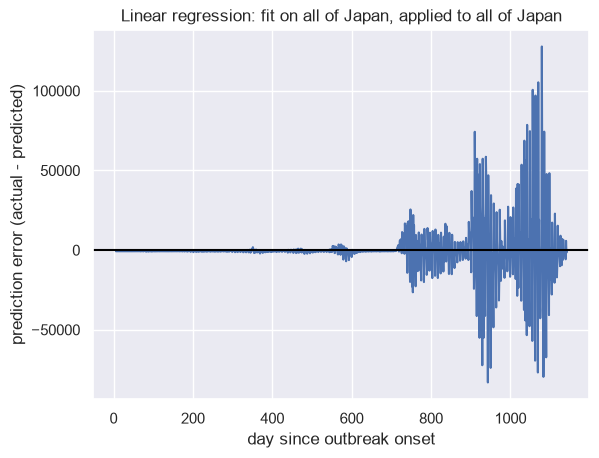

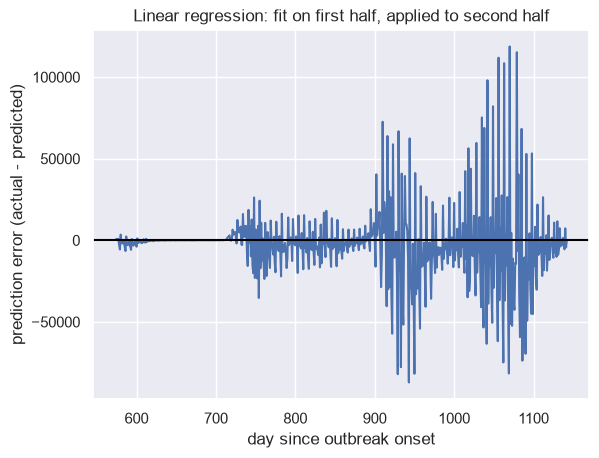

In [4]:
error_reg_a = lagdat["Y"] - pred_a
error_reg_b = testingDat["Y"] - pred_b

plt.plot(lagdat["day"], error_reg_a)
plt.axhline(0, color="black")
plt.xlabel("day since outbreak onset")
plt.ylabel("prediction error (actual - predicted)")
plt.title("Linear regression: fit on all of Japan, applied to all of Japan")
plt.show()

plt.plot(testingDat["day"], error_reg_b)
plt.axhline(0, color="black")
plt.xlabel("day since outbreak onset")
plt.ylabel("prediction error (actual - predicted)")
plt.title("Linear regression: fit on first half, applied to second half")
plt.show()


### Neural network setup

I used the same five previous-day case counts from Homework 9 to predict the current day's cases in Japan. I compared linear regression with two neural networks:

- A network with one hidden layer of 2 nodes.
- A network with two hidden layers of 2 nodes each.

Both networks use fully connected layers, ReLU for the hidden layers, a linear output, and MSE for the loss.

I scaled the data before training because the case counts are large. I then changed the predictions back to the original scale before calculating MSE so I could compare them with linear regression.

I tried different random seeds because the neural network sometimes gave different results. I used seed 7 for the two-layer network in the comparisons below.

In [5]:
def make_tensors(x_df, y_series, x_mean, x_std, y_mean, y_std):
    x_scaled = (x_df - x_mean) / x_std
    y_scaled = (y_series - y_mean) / y_std
    x_tensor = torch.tensor(x_scaled.values, dtype=torch.float32)
    y_tensor = torch.tensor(y_scaled.values, dtype=torch.float32).unsqueeze(1)
    return x_tensor, y_tensor

In [6]:
def train_network(model, x_train, y_train, epochs, lr):
    loss_fn = torch.nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    for epoch in range(epochs):
        y_pred = model(x_train)
        loss = loss_fn(y_pred, y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if epoch % 1000 == 0:
            print("epoch", epoch, "loss", loss.item())
    return model

In [7]:
torch.manual_seed(1)

x_mean_a = lagdat[x_cols].mean()
x_std_a = lagdat[x_cols].std()
y_mean_a = lagdat["Y"].mean()
y_std_a = lagdat["Y"].std()

x_train_a, y_train_a = make_tensors(lagdat[x_cols], lagdat["Y"], x_mean_a, x_std_a, y_mean_a, y_std_a)

nn1_a = torch.nn.Sequential(
    torch.nn.Linear(5, 2),   
    torch.nn.ReLU(),
    torch.nn.Linear(2, 1))
nn1_a = train_network(nn1_a, x_train_a, y_train_a, epochs=5000, lr=0.05)

pred_scaled = nn1_a(x_train_a).detach().numpy().reshape(-1)
pred_real = pred_scaled * y_std_a + y_mean_a
error_nn1_a = lagdat["Y"].values - pred_real
mse_nn1_a = (error_nn1_a ** 2).mean()
print("nn1 (2 nodes) mse_a:", mse_nn1_a)

epoch 0 loss 1.2288795709609985
epoch 1000 loss 0.0825681984424591
epoch 2000 loss 0.08201136440038681
epoch 3000 loss 0.08167511969804764
epoch 4000 loss 0.08151903748512268
nn1 (2 nodes) mse_a: 211941763.93755764


In [8]:
def quick_train_loss(seed, x_train, y_train, epochs=3000, lr=0.05):
    torch.manual_seed(seed)
    model = torch.nn.Sequential(
        torch.nn.Linear(5, 2),
        torch.nn.ReLU(),
        torch.nn.Linear(2, 2),
        torch.nn.ReLU(),
        torch.nn.Linear(2, 1)
    )
    loss_fn = torch.nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    for epoch in range(epochs):
        y_pred = model(x_train)
        loss = loss_fn(y_pred, y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return loss.item()

for seed in range(1, 11):
    final_loss = quick_train_loss(seed, x_train_a, y_train_a)
    print("seed", seed, "final loss", final_loss)

seed 1 final loss 0.9991204738616943
seed 2 final loss 0.05592479556798935
seed 3 final loss 0.08188314735889435
seed 4 final loss 0.07420969754457474
seed 5 final loss 0.08213276416063309
seed 6 final loss 0.05202804133296013
seed 7 final loss 0.07928823679685593
seed 8 final loss 0.050802525132894516
seed 9 final loss 0.9991204738616943
seed 10 final loss 0.05589182302355766


In [9]:
x_mean_b = trainingDat[x_cols].mean()
x_std_b = trainingDat[x_cols].std()
y_mean_b = trainingDat["Y"].mean()
y_std_b = trainingDat["Y"].std()

x_train_b, y_train_b = make_tensors(trainingDat[x_cols], trainingDat["Y"], x_mean_b, x_std_b, y_mean_b, y_std_b)
x_test_b, y_test_b = make_tensors(testingDat[x_cols], testingDat["Y"], x_mean_b, x_std_b, y_mean_b, y_std_b)

torch.manual_seed(1)
nn1_b = torch.nn.Sequential(
    torch.nn.Linear(5, 2),
    torch.nn.ReLU(),
    torch.nn.Linear(2, 1)
)
nn1_b = train_network(nn1_b, x_train_b, y_train_b, epochs=5000, lr=0.05)

pred_scaled = nn1_b(x_test_b).detach().numpy().reshape(-1)
pred_real = pred_scaled * y_std_b + y_mean_b
error_nn1_b = testingDat["Y"].values - pred_real
mse_nn1_b = (error_nn1_b ** 2).mean()
print("nn1 (2 nodes) mse_b:", mse_nn1_b)

epoch 0 loss 1.2360749244689941
epoch 1000 loss 0.038372140377759933
epoch 2000 loss 0.036005791276693344
epoch 3000 loss 0.0353509746491909
epoch 4000 loss 0.035120878368616104
nn1 (2 nodes) mse_b: 544676060.0685368


In [10]:
torch.manual_seed(7)
nn2_a = torch.nn.Sequential(
    torch.nn.Linear(5, 2),
    torch.nn.ReLU(),
    torch.nn.Linear(2, 2),
    torch.nn.ReLU(),
    torch.nn.Linear(2, 1)
)
nn2_a = train_network(nn2_a, x_train_a, y_train_a, epochs=5000, lr=0.05)

pred_scaled = nn2_a(x_train_a).detach().numpy().reshape(-1)
pred_real = pred_scaled * y_std_a + y_mean_a
error_nn2_a = lagdat["Y"].values - pred_real
mse_nn2_a = (error_nn2_a ** 2).mean()
print("nn2 (4 nodes/2 layers) mse_a:", mse_nn2_a)

epoch 0 loss 1.40386962890625
epoch 1000 loss 0.07899823039770126
epoch 2000 loss 0.0810953825712204
epoch 3000 loss 0.07946417480707169
epoch 4000 loss 0.08103207498788834
nn2 (4 nodes/2 layers) mse_a: 207594427.54939404


In [11]:
x_mean_b = trainingDat[x_cols].mean()
x_std_b = trainingDat[x_cols].std()
y_mean_b = trainingDat["Y"].mean()
y_std_b = trainingDat["Y"].std()

x_train_b, y_train_b = make_tensors(trainingDat[x_cols], trainingDat["Y"], x_mean_b, x_std_b, y_mean_b, y_std_b)
x_test_b, y_test_b = make_tensors(testingDat[x_cols], testingDat["Y"], x_mean_b, x_std_b, y_mean_b, y_std_b)

torch.manual_seed(7)   
nn2_b = torch.nn.Sequential(
    torch.nn.Linear(5, 2),
    torch.nn.ReLU(),
    torch.nn.Linear(2, 2),
    torch.nn.ReLU(),
    torch.nn.Linear(2, 1)
)
nn2_b = train_network(nn2_b, x_train_b, y_train_b, epochs=5000, lr=0.05)

pred_scaled = nn2_b(x_test_b).detach().numpy().reshape(-1)
pred_real = pred_scaled * y_std_b + y_mean_b
error_nn2_b = testingDat["Y"].values - pred_real
mse_nn2_b = (error_nn2_b ** 2).mean()
print("nn2 (4 nodes/2 layers) mse_b:", mse_nn2_b)

epoch 0 loss 1.403767704963684
epoch 1000 loss 0.06813608109951019
epoch 2000 loss 0.05470187962055206
epoch 3000 loss 0.06180223822593689
epoch 4000 loss 0.0452059842646122
nn2 (4 nodes/2 layers) mse_b: 5153702171.811891


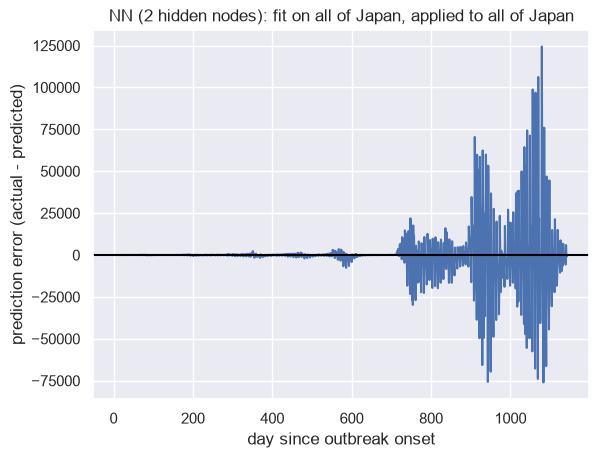

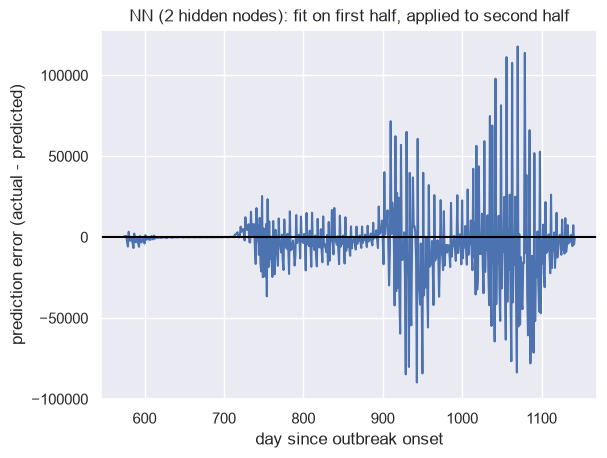

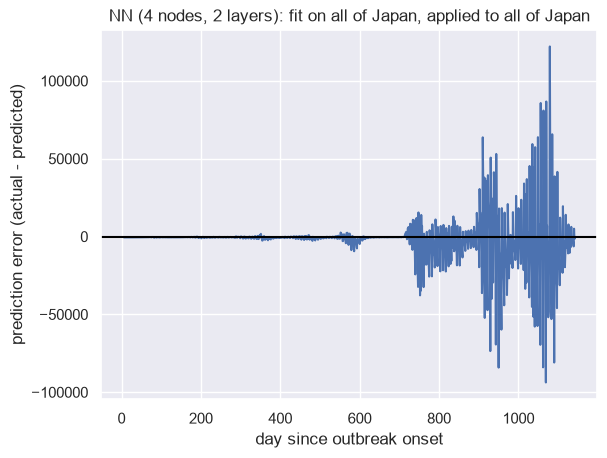

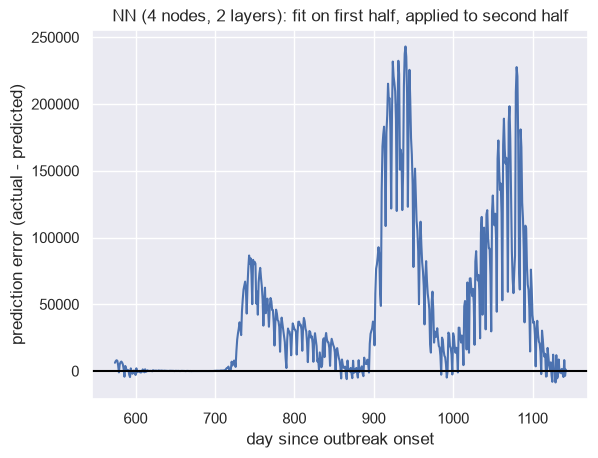

In [12]:
plt.plot(lagdat["day"], error_nn1_a)
plt.axhline(0, color="black")
plt.xlabel("day since outbreak onset")
plt.ylabel("prediction error (actual - predicted)")
plt.title("NN (2 hidden nodes): fit on all of Japan, applied to all of Japan")
plt.show()

plt.plot(testingDat["day"], error_nn1_b)
plt.axhline(0, color="black")
plt.xlabel("day since outbreak onset")
plt.ylabel("prediction error (actual - predicted)")
plt.title("NN (2 hidden nodes): fit on first half, applied to second half")
plt.show()

plt.plot(lagdat["day"], error_nn2_a)
plt.axhline(0, color="black")
plt.xlabel("day since outbreak onset")
plt.ylabel("prediction error (actual - predicted)")
plt.title("NN (4 nodes, 2 layers): fit on all of Japan, applied to all of Japan")
plt.show()

plt.plot(testingDat["day"], error_nn2_b)
plt.axhline(0, color="black")
plt.xlabel("day since outbreak onset")
plt.ylabel("prediction error (actual - predicted)")
plt.title("NN (4 nodes, 2 layers): fit on first half, applied to second half")
plt.show()

In [13]:
report = pd.DataFrame({
    "method": ["linear regression", "NN: 2 hidden nodes", "NN: 4 nodes (2 layers)"],
    "MSE (fit all, test all)": [mse_a, mse_nn1_a, mse_nn2_a],
    "MSE (fit first half, test second half)": [mse_b, mse_nn1_b, mse_nn2_b]
})
report

,method,"MSE (fit all, test all)","MSE (fit first half, test second half)"
0,linear regression,2.155953e+08,5.278290e+08
1,NN: 2 hidden nodes,2.119418e+08,5.446761e+08
2,NN: 4 nodes (2 layers),2.075944e+08,5.153702e+09


In [14]:
report_display = report.copy()
for col in ["MSE (fit all, test all)", "MSE (fit first half, test second half)"]:
    report_display[col] = report_display[col].map(lambda x: f"{x:,.0f}")
report_display

,method,"MSE (fit all, test all)","MSE (fit first half, test second half)"
0,linear regression,"215,595,319","527,829,034"
1,NN: 2 hidden nodes,"211,941,764","544,676,060"
2,NN: 4 nodes (2 layers),"207,594,428","5,153,702,172"


### Results and interpretation

The table above compares the mean squared errors (MSE) for linear regression and the two neural networks. A lower MSE means the predictions were closer to the actual case counts.

When I trained and tested on all of Japan's data, the network with two hidden layers had the lowest MSE. However, the three models had fairly similar results.

When I trained on the first half of the data and tested on the second half, linear regression had the lowest MSE. The network with 2 hidden nodes was close to linear regression, but the network with two hidden layers had a much larger error.

The case counts in the second half of the data were much higher than in the first half. This may explain why the models had more trouble predicting the second half, especially the larger neural network. The results show that a network that fits its training data well does not always predict new data better. The neural network results can also change depending on the random seed used during training.